# 01 — EDA and the accuracy trap
**Business goal (agreed):** catch at least **80% of fraud** (recall) while at least **70% of alerts are real fraud** (precision).
**Primary metric:** PR-AUC. The final block/approve decision comes from the minimum-cost threshold (notebook 05).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

from src import config
from src.preprocess import load_data, train_test
from src.train import cv_splitter

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("Goal: recall >=", config.TARGET_RECALL, "| precision >=", config.TARGET_PRECISION, "| C_FP =", config.C_FP)

Goal: recall >= 0.8 | precision >= 0.7 | C_FP = 5.0


## Step 1 — Load and inspect

In [2]:
df = load_data()
df.info(verbose=False)

Shape: (284807, 31)
Missing values: 0


Duplicate rows: 1081


Shape after dropping duplicates: (283726, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 283726 entries, 0 to 283725
Columns: 31 entries, Time to Class
dtypes: float64(30), int32(1)
memory usage: 66.0 MB


In [3]:
counts = df[config.TARGET].value_counts()
print(counts)
print(f"Fraud: {counts[1]} of {len(df)} = {counts[1] / len(df):.3%}  (about 1 in {len(df) // counts[1]})")

Class
0    283253
1       473
Name: count, dtype: int64
Fraud: 473 of 283726 = 0.167%  (about 1 in 599)


## Step 2 — Explore

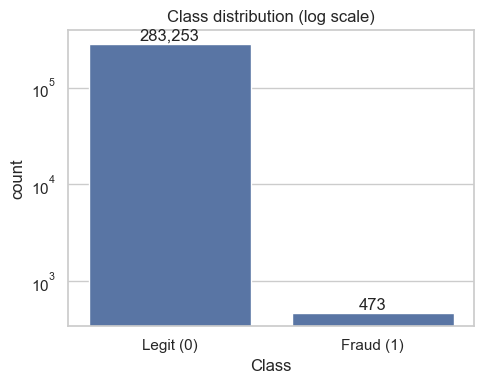

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=config.TARGET, data=df, ax=ax)
ax.set_yscale("log")
ax.set_xticks([0, 1], ["Legit (0)", "Fraud (1)"])
ax.set_title("Class distribution (log scale)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "01_class_distribution.png", dpi=150); plt.show()

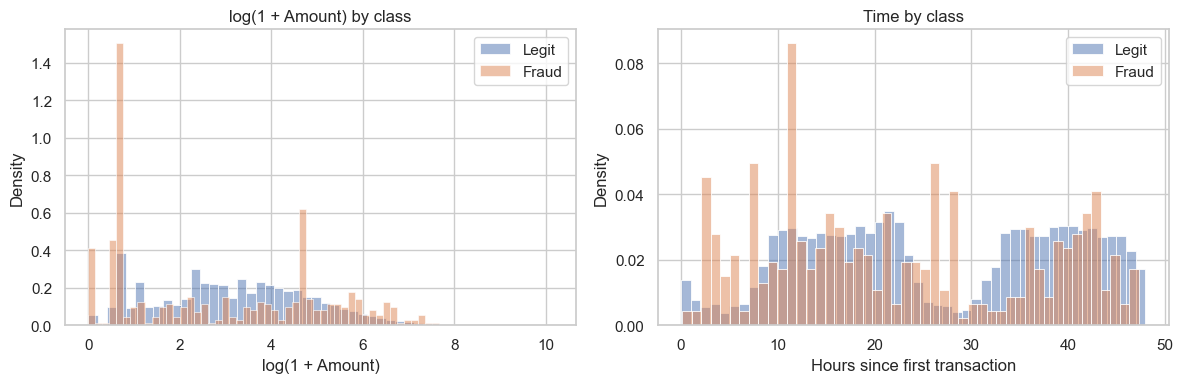

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls, label in [(0, "Legit"), (1, "Fraud")]:
    sub = df[df[config.TARGET] == cls]
    sns.histplot(np.log1p(sub["Amount"]), bins=50, stat="density", ax=axes[0], label=label, alpha=0.5)
    sns.histplot(sub["Time"] / 3600, bins=48, stat="density", ax=axes[1], label=label, alpha=0.5)
axes[0].set(title="log(1 + Amount) by class", xlabel="log(1 + Amount)")
axes[1].set(title="Time by class", xlabel="Hours since first transaction")
for a in axes: a.legend()
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "01_amount_time_by_class.png", dpi=150); plt.show()

In [6]:
print(df.groupby(config.TARGET)["Amount"].describe().round(2))
hour = (df["Time"] // 3600) % 24
night = hour < 6
print(f"\nShare of transactions between 00:00-06:00 (approx. hour of day): "
      f"legit {night[df.Class == 0].mean():.1%}, fraud {night[df.Class == 1].mean():.1%}")

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87

Share of transactions between 00:00-06:00 (approx. hour of day): legit 8.4%, fraud 24.3%


**Observations for slides** (numbers printed above):
- Fraud is extremely rare: about 1 in 600 transactions after removing duplicates.
- Typical fraud amounts are small (median is lower than for legit), but the fraud amount distribution has a long tail.
- Fraud is spread across the day, while legit traffic drops at night — so fraud makes up a larger *share* of night-time traffic.

## Step 3 — Split (X_test is locked from here)

In [7]:
X_train, X_test, y_train, y_test = train_test(df)
print(f"Train: {X_train.shape}, fraud {y_train.mean():.3%}")
print(f"Test:  {X_test.shape}, fraud {y_test.mean():.3%}")

Train: (226980, 30), fraud 0.167%
Test:  (56746, 30), fraud 0.167%


## Step 4 — Baseline: the accuracy trap
A dummy model that always says "legit", evaluated with 5-fold CV on the training data only.

In [8]:
dummy = DummyClassifier(strategy="most_frequent")
res = cross_validate(dummy, X_train, y_train, cv=cv_splitter(),
                     scoring={"accuracy": "accuracy", "recall": "recall", "pr_auc": "average_precision"})
acc, rec, ap = res["test_accuracy"].mean(), res["test_recall"].mean(), res["test_pr_auc"].mean()
print(f"Dummy accuracy: {acc:.4%}")
print(f"Dummy recall:   {rec:.0%}  -> catches zero fraud")
print(f"Dummy PR-AUC:   {ap:.4f}  (= fraud rate; the floor every model must beat)")

Dummy accuracy: 99.8335%
Dummy recall:   0%  -> catches zero fraud
Dummy PR-AUC:   0.0017  (= fraud rate; the floor every model must beat)


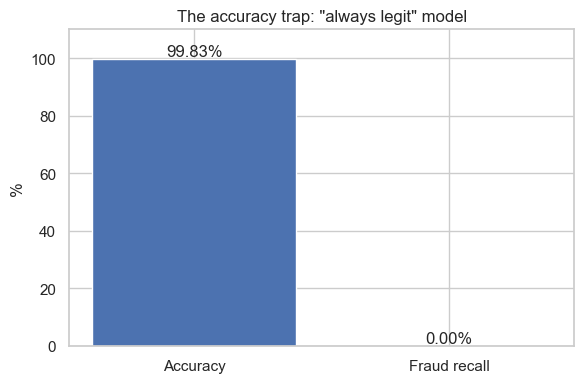

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Accuracy", "Fraud recall"], [acc * 100, rec * 100], color=["#4c72b0", "#c44e52"])
ax.bar_label(bars, fmt="%.2f%%")
ax.set_ylim(0, 110); ax.set_ylabel("%")
ax.set_title('The accuracy trap: "always legit" model')
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "01_accuracy_trap.png", dpi=150); plt.show()